# 09 · Baseline machine learning

## Purpose

Establish dummy and logistic-regression baselines before comparing more flexible models.

## Method

Use the same stratified folds, preprocessing rules, primary ROC-AUC, minority-sensitive PR-AUC, threshold metrics, runtime, and memory delta for both baseline families.

## Interpretation

Use the displayed tables, figures, and saved metrics produced by this run. Do not fill this section with assumed outcomes. For every result, distinguish observed evidence from interpretation.

## Limitations

Fold metrics are internal cross-validation estimates and may vary with the split. Accuracy is not used as the sole selection criterion.

## References

Scikit-learn model evaluation: https://scikit-learn.org/stable/modules/model_evaluation.html


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
while not (ROOT / 'returnwise').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from IPython.display import display
from returnwise.research_state import load_state, save_state
state = load_state()
print('Project:', ROOT)
print('Notebook:', '09 · Baseline machine learning')


Project: C:\Users\Lenovo\Documents\Who is back
Notebook: 09 · Baseline machine learning


,model,folds,roc_auc,pr_auc,accuracy,balanced_accuracy,precision,recall,f1,roc_auc_std,pr_auc_std,accuracy_std,balanced_accuracy_std,precision_std,recall_std,f1_std,mean_fit_seconds,mean_inference_seconds,mean_rss_delta_mb,status
0,Logistic regression,3,0.585437,0.551053,0.560881,0.560542,0.536196,0.553855,0.544875,0.003905,0.002281,0.002312,0.00213,0.002628,0.003047,0.001331,2.356295,0.356993,4.045573,completed
1,Dummy (prior),3,0.500000,0.474594,0.525406,0.500000,0.000000,0.000000,0.000000,0.000000,0.000009,0.000009,0.00000,0.000000,0.000000,0.000000,1.487922,0.320719,6.920573,completed


,model,fold,roc_auc,pr_auc,accuracy,balanced_accuracy,precision,recall,f1,confusion_matrix_tn_fp_fn_tp,fit_seconds,inference_seconds,rss_delta_mb,status
0,Dummy (prior),1,0.500000,0.474594,0.525406,0.500000,0.000000,0.000000,0.000000,"[28022, 0, 25312, 0]",1.339836,0.590770,10.753906,completed
1,Dummy (prior),2,0.500000,0.474584,0.525416,0.500000,0.000000,0.000000,0.000000,"[28022, 0, 25311, 0]",1.673412,0.166932,5.015625,completed
2,Dummy (prior),3,0.500000,0.474603,0.525397,0.500000,0.000000,0.000000,0.000000,"[28021, 0, 25312, 0]",1.450519,0.204457,4.992188,completed
3,Logistic regression,1,0.581057,0.548867,0.558237,0.558130,0.533167,0.556021,0.544354,"[15699, 12323, 11238, 14074]",1.659841,0.173455,3.097656,completed
4,Logistic regression,2,0.588551,0.553418,0.562522,0.562167,0.537876,0.555174,0.546388,"[15949, 12073, 11259, 14052]",2.693499,0.668157,5.804688,completed
5,Logistic regression,3,0.586705,0.550874,0.561885,0.561328,0.537544,0.550371,0.543882,"[16036, 11985, 11381, 13931]",2.715546,0.229368,3.234375,completed


Unavailable or failed: {'CatBoost': 'Optional dependency `catboost` is not installed.', 'LightGBM': 'Optional dependency `lightgbm` is not installed.', 'XGBoost': 'Optional dependency `xgboost` is not installed.', 'TabPFN': 'Optional dependency `tabpfn` is not installed.'}


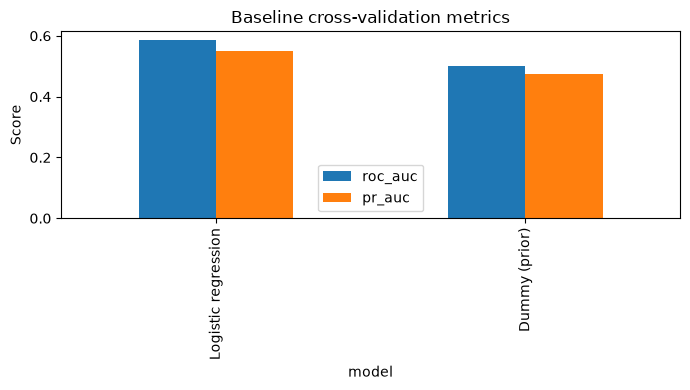

In [2]:
from returnwise.models import benchmark_models
from returnwise.research_state import load_state, save_state
import matplotlib.pyplot as plt

state = load_state()
if 'X_train' not in state:
    raise RuntimeError('Run notebook 07 first.')
baseline_results, baseline_folds, baseline_skipped = benchmark_models(
    state['X_train'], state['y_train'], mode=state.get('experiment_mode', 'quick'), model_names=['Dummy (prior)', 'Logistic regression']
)
display(baseline_results)
display(baseline_folds)
print('Unavailable or failed:', baseline_skipped)
ax = baseline_results.plot.bar(x='model', y=['roc_auc', 'pr_auc'], figsize=(7, 4), title='Baseline cross-validation metrics')
ax.set_ylabel('Score')
plt.tight_layout()
plt.show()
state.update({'baseline_results': baseline_results, 'baseline_folds': baseline_folds,
              'baseline_skipped': baseline_skipped})
from returnwise.experiments import log_experiment
log_experiment('Baseline machine learning benchmark', None,
               {'results': baseline_results.to_dict(orient='records')}, {'mode': state.get('experiment_mode', 'quick')})
save_state(state)
